# DSC 411/511
# Clustering on Ames: k-means and Hierarchical


---
# Section 0: Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sns.set_style('whitegrid')
SEED = 42
print('ready')

ready


In [2]:
DATA_URL = 'https://jse.amstat.org/v19n3/decock/AmesHousing.txt'
df = pd.read_csv(DATA_URL, sep='\t')       # tab separated
print('Rows   :', df.shape[0])
print('Columns:', df.shape[1])

Rows   : 2930
Columns: 82


## 0.1 Which columns, and why not all of them

Clustering on 36 columns gives groups nobody can describe. We pick a small set a
realtor would actually talk about.

**`SalePrice` is deliberately left out.** If we cluster on price, of course the
groups differ by price. That would be circular. We cluster on everything except
price, then look at what the groups cost.

In [3]:
FEATURES = [
    'Gr Liv Area',      # above ground living area
    'Lot Area',         # lot size
    'Overall Qual',     # overall quality, 1 to 10
    'Year Built',
    'Total Bsmt SF',    # basement size
    'Garage Area',
    'TotRms AbvGrd',    # total rooms above ground
    'Full Bath',
]

work = df[FEATURES + ['SalePrice', 'Neighborhood']].copy()
work[FEATURES] = work[FEATURES].fillna(work[FEATURES].median())

X = work[FEATURES]
print(f'Clustering on {X.shape[1]} columns, {X.shape[0]:,} houses')
print()
print('SalePrice in the feature list?', 'SalePrice' in FEATURES, ' <- must be False')
print()
print(X.describe().T[['min', '50%', 'max']].round(0).to_string())

Clustering on 8 columns, 2,930 houses

SalePrice in the feature list? False  <- must be False

                  min     50%       max
Gr Liv Area     334.0  1442.0    5642.0
Lot Area       1300.0  9436.0  215245.0
Overall Qual      1.0     6.0      10.0
Year Built     1872.0  1973.0    2010.0
Total Bsmt SF     0.0   990.0    6110.0
Garage Area       0.0   480.0    1488.0
TotRms AbvGrd     2.0     6.0      15.0
Full Bath         0.0     2.0       4.0


## 0.2 Scaling is not optional

Both methods today are built on distance. You proved on Sep 02 what happens when
the columns have different ranges.

In [4]:
rng = (X.max() - X.min()).sort_values(ascending=False)
print('Column ranges, widest first:')
print(rng.round(0).to_string())
print()
print(f'Lot Area spans {rng.iloc[0]/rng.iloc[-1]:,.0f} times more than the narrowest column.')
print('Unscaled, k-means would be clustering on Lot Area and almost nothing else.')

Column ranges, widest first:
Lot Area         213945.0
Total Bsmt SF      6110.0
Gr Liv Area        5308.0
Garage Area        1488.0
Year Built          138.0
TotRms AbvGrd        13.0
Overall Qual          9.0
Full Bath             4.0

Lot Area spans 53,486 times more than the narrowest column.
Unscaled, k-means would be clustering on Lot Area and almost nothing else.


In [5]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

print('After standardizing:')
print(pd.DataFrame(Xs, columns=FEATURES).agg(['mean', 'std']).T.round(3).to_string())

After standardizing:
               mean  std
Gr Liv Area     0.0  1.0
Lot Area        0.0  1.0
Overall Qual   -0.0  1.0
Year Built     -0.0  1.0
Total Bsmt SF  -0.0  1.0
Garage Area     0.0  1.0
TotRms AbvGrd  -0.0  1.0
Full Bath       0.0  1.0


---
# Section 1: How Many Clusters?

k-means makes you choose k before it will run. Two tools help, and neither gives
you an answer.

In [6]:
ks = range(2, 11)
inertia, sil = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))

tbl = pd.DataFrame({'k': list(ks),
                    'inertia': np.round(inertia, 0),
                    'silhouette': np.round(sil, 4)})
tbl['inertia drop'] = tbl['inertia'].diff(-1).round(0)
print(tbl.to_string(index=False))

 k  inertia  silhouette  inertia drop
 2  15748.0      0.3203        2058.0
 3  13690.0      0.2587        1388.0
 4  12302.0      0.2642        1452.0
 5  10850.0      0.2685         818.0
 6  10032.0      0.2039         607.0
 7   9425.0      0.1871         505.0
 8   8920.0      0.1822         392.0
 9   8528.0      0.1867         366.0
10   8162.0      0.1898           NaN


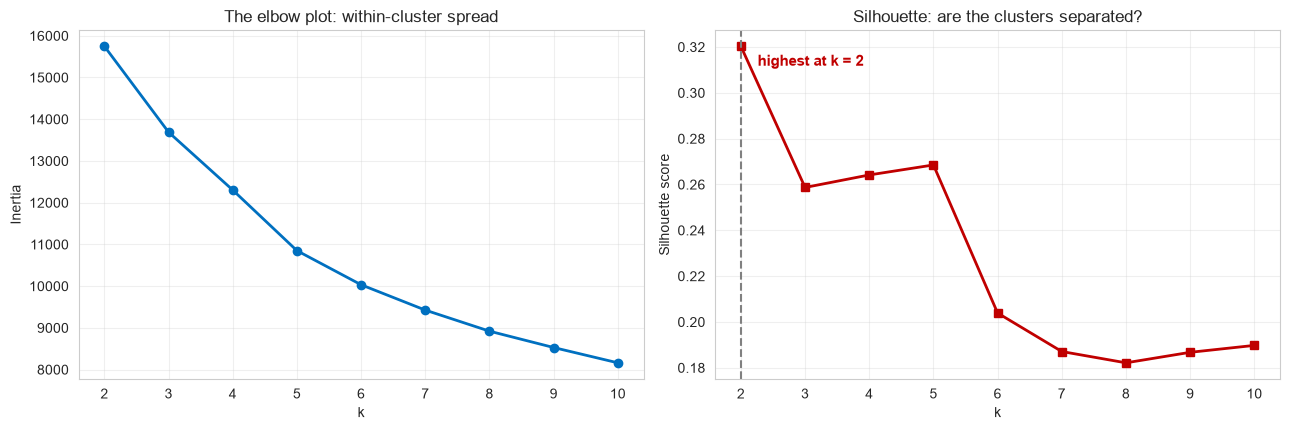

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))

ax[0].plot(list(ks), inertia, 'o-', lw=2, color='#0070C0')
ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia')
ax[0].set_title('The elbow plot: within-cluster spread')
ax[0].grid(alpha=.3)

ax[1].plot(list(ks), sil, 's-', lw=2, color='#C00000')
best_k = list(ks)[int(np.argmax(sil))]
ax[1].axvline(best_k, color='grey', ls='--', lw=1.5)
ax[1].annotate(f'highest at k = {best_k}', (best_k, max(sil)),
               textcoords='offset points', xytext=(12, -14),
               fontsize=11, fontweight='bold', color='#C00000')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhouette score')
ax[1].set_title('Silhouette: are the clusters separated?')
ax[1].grid(alpha=.3)

plt.tight_layout(); plt.show()

### How to read these

**Inertia** is the total squared distance from every house to its own centroid.
It always falls as k rises, so the lowest inertia is not the best k. You are
looking for the **bend**, where adding another cluster stops buying you much.

**Silhouette** runs from -1 to 1 and asks, for each house: am I closer to my own
cluster than to the nearest other cluster? Higher is better separated.

**Both are guides, not answers.** They often disagree, and on real data the elbow
is usually a gentle curve rather than a corner.

In [8]:
print(f'Silhouette says      k = {best_k}')
print()
print('Silhouette scores, in context:')
print('   above 0.50   clear, well separated structure')
print('   0.25 to 0.50 some structure, but the clusters overlap')
print('   below 0.25   little or no real cluster structure')
print()
print(f'Our best score is {max(sil):.3f}.')
print()
print('Be honest about what that means before you present any of this.')

Silhouette says      k = 2

Silhouette scores, in context:
   above 0.50   clear, well separated structure
   0.25 to 0.50 some structure, but the clusters overlap
   below 0.25   little or no real cluster structure

Our best score is 0.320.

Be honest about what that means before you present any of this.


---
# Section 2: Fit k-means and Look at the Groups

In [9]:
K = 4          # change this. Try the elbow value and the silhouette value.

km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Xs)
work['kmeans'] = km.labels_

print(f'k = {K}')
print()
print('Cluster sizes:')
for c, n in work['kmeans'].value_counts().sort_index().items():
    print(f'   cluster {c}: {n:>5,} houses  ({n/len(work)*100:>4.1f}%)')
print()
print(f'Silhouette at k={K}: {silhouette_score(Xs, km.labels_):.4f}')

k = 4

Cluster sizes:
   cluster 0:   919 houses  (31.4%)
   cluster 1: 1,204 houses  (41.1%)
   cluster 2:   430 houses  (14.7%)
   cluster 3:   377 houses  (12.9%)

Silhouette at k=4: 0.2642


In [10]:
# The profile table. This is the output that actually matters.
profile = work.groupby('kmeans')[FEATURES + ['SalePrice']].mean().round(0)
profile['houses'] = work['kmeans'].value_counts().sort_index()
print('AVERAGE HOUSE IN EACH CLUSTER')
print(profile.to_string())

AVERAGE HOUSE IN EACH CLUSTER
        Gr Liv Area  Lot Area  Overall Qual  Year Built  Total Bsmt SF  Garage Area  TotRms AbvGrd  Full Bath  SalePrice  houses
kmeans                                                                                                                          
0            1543.0    9134.0           7.0      1995.0         1118.0        516.0            6.0        2.0   198482.0     919
1            1106.0    8687.0           5.0      1955.0          856.0        358.0            5.0        1.0   126344.0    1204
2            2208.0   15199.0           8.0      1997.0         1607.0        771.0            8.0        2.0   315219.0     430
3            1845.0   11524.0           6.0      1938.0          881.0        395.0            8.0        2.0   158264.0     377


**`SalePrice` is in that table but was never used to build the clusters.**

If the clusters differ in price, that came out of the other columns by itself.
That is a finding, not a setup.

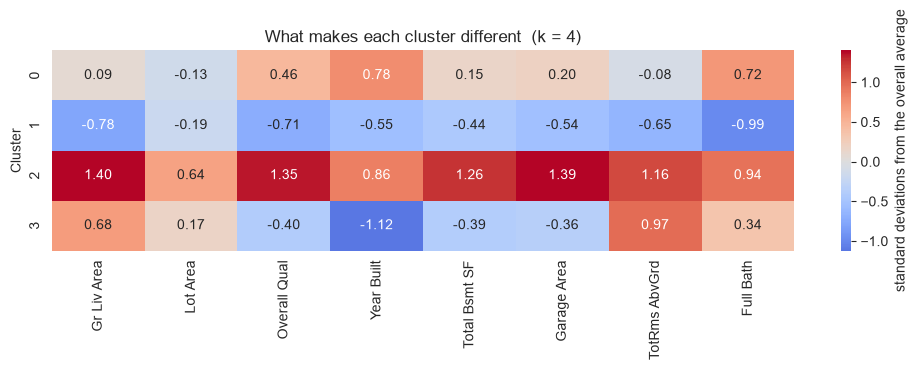

Red means above average for that column. Blue means below.
Read across a row and you have that cluster described in one sentence.


In [11]:
# Same table as z-scores, so you can see which columns define each cluster
z = pd.DataFrame(Xs, columns=FEATURES)
z['kmeans'] = km.labels_
zprof = z.groupby('kmeans').mean().round(2)

plt.figure(figsize=(10, 3.6))
sns.heatmap(zprof, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            cbar_kws={'label': 'standard deviations from the overall average'})
plt.title(f'What makes each cluster different  (k = {K})')
plt.ylabel('Cluster'); plt.tight_layout(); plt.show()

print('Red means above average for that column. Blue means below.')
print('Read across a row and you have that cluster described in one sentence.')

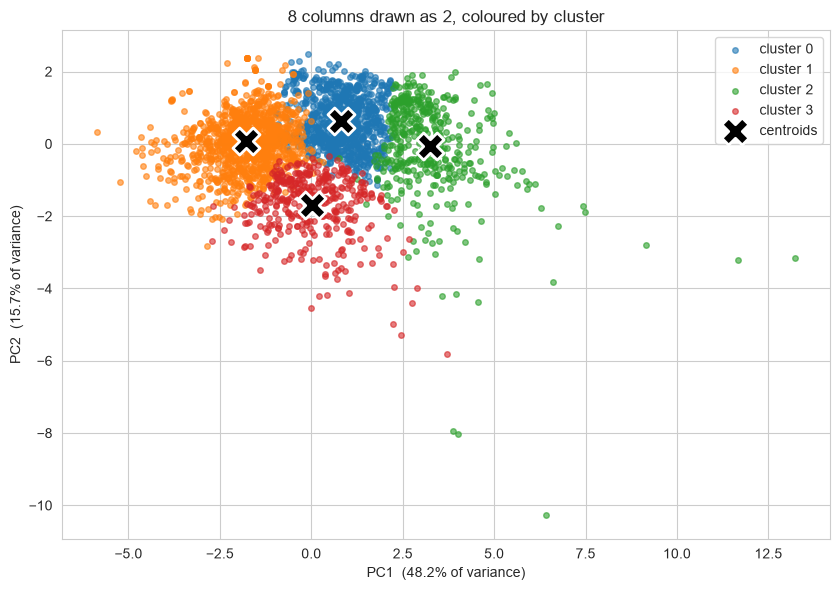

You are looking at 63.9% of the information.
Clusters that look overlapping here may be well separated in the other dimensions.


In [12]:
# Draw the clusters on two principal components, purely to see them
p2 = PCA(n_components=2).fit(Xs)
Z2 = p2.transform(Xs)

plt.figure(figsize=(8.5, 6))
for c in range(K):
    m = km.labels_ == c
    plt.scatter(Z2[m, 0], Z2[m, 1], s=16, alpha=.6, label=f'cluster {c}')
cent = p2.transform(km.cluster_centers_)
plt.scatter(cent[:, 0], cent[:, 1], marker='X', s=380, c='black',
            edgecolors='white', linewidths=2, zorder=9, label='centroids')
plt.xlabel(f'PC1  ({p2.explained_variance_ratio_[0]*100:.1f}% of variance)')
plt.ylabel(f'PC2  ({p2.explained_variance_ratio_[1]*100:.1f}% of variance)')
plt.title(f'{len(FEATURES)} columns drawn as 2, coloured by cluster')
plt.legend(); plt.tight_layout(); plt.show()

print(f'You are looking at {p2.explained_variance_ratio_[:2].sum()*100:.1f}% of the information.')
print('Clusters that look overlapping here may be well separated in the other dimensions.')

---
# Section 3: Naming the Clusters

The algorithm gave you cluster 0, 1, 2, 3. Those are not findings. Turning them
into something a realtor would say is the actual work, and only you can do it.

In [13]:
print('DESCRIBE EACH CLUSTER IN ONE LINE')
print()
overall = X.mean()
for c in range(K):
    sub = work[work['kmeans'] == c]
    diffs = ((sub[FEATURES].mean() - overall) / X.std()).sort_values(key=abs, ascending=False)
    top = diffs.head(3)
    bits = [f'{n} {"high" if v > 0 else "low"}' for n, v in top.items()]
    print(f'Cluster {c}  ({len(sub):>5,} houses,  average price ${sub.SalePrice.mean():>8,.0f})')
    print(f'   defined by: {", ".join(bits)}')
    print(f'   built around {sub["Year Built"].mean():.0f}, '
          f'{sub["Gr Liv Area"].mean():,.0f} sq ft, quality {sub["Overall Qual"].mean():.1f}')
    print()

DESCRIBE EACH CLUSTER IN ONE LINE

Cluster 0  (  919 houses,  average price $ 198,482)
   defined by: Year Built high, Full Bath high, Overall Qual high
   built around 1995, 1,543 sq ft, quality 6.7

Cluster 1  (1,204 houses,  average price $ 126,344)
   defined by: Full Bath low, Gr Liv Area low, Overall Qual low
   built around 1955, 1,106 sq ft, quality 5.1

Cluster 2  (  430 houses,  average price $ 315,219)
   defined by: Gr Liv Area high, Garage Area high, Overall Qual high
   built around 1997, 2,208 sq ft, quality 8.0

Cluster 3  (  377 houses,  average price $ 158,264)
   defined by: Year Built low, TotRms AbvGrd high, Gr Liv Area high
   built around 1938, 1,845 sq ft, quality 5.5



---
# Section 4: Hierarchical, and the Dendrogram

No k required. Build the whole tree, then decide where to cut it.

**2,930 houses would give an unreadable dendrogram.** We take a sample to draw it,
then run the full method separately.

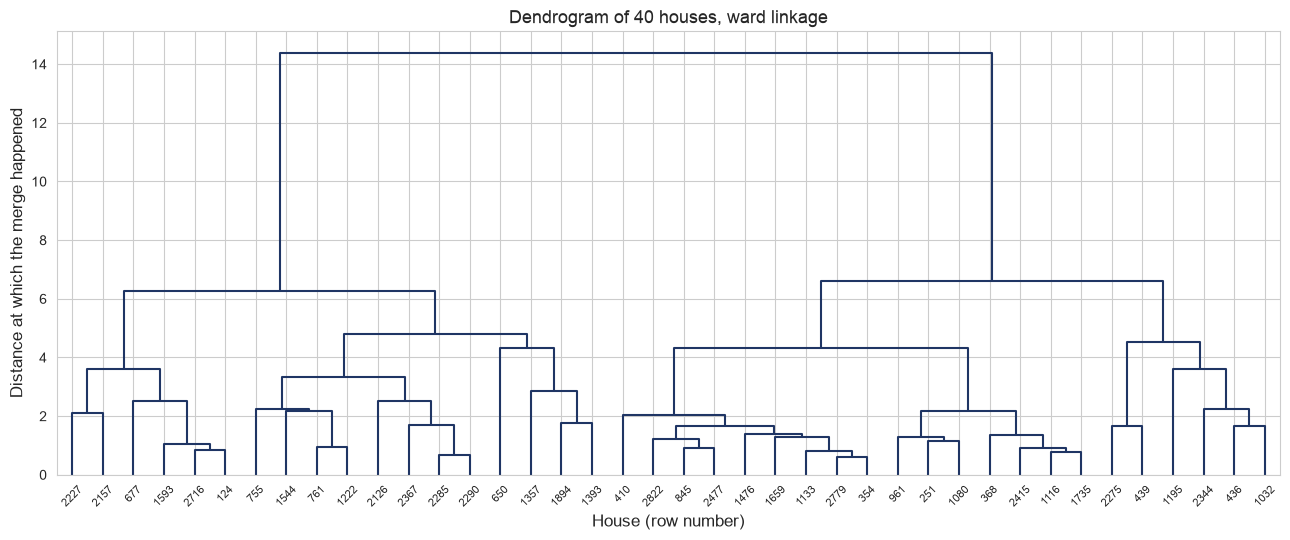

HOW TO READ IT
  The HEIGHT of each join is the distance at which the merge happened.
  Low join  = those houses are similar.
  High join = merged only because nothing closer was left.

  The left-to-right ORDER along the bottom means nothing.
  Two houses side by side may not be similar at all.


In [14]:
SAMPLE_N = 40
samp = work.sample(SAMPLE_N, random_state=SEED)
Xs_samp = scaler.transform(samp[FEATURES])

Z = linkage(Xs_samp, method='ward')

plt.figure(figsize=(13, 5.5))
dendrogram(Z, labels=samp.index.tolist(), leaf_font_size=8,
           color_threshold=0, above_threshold_color='#1F3564')
plt.ylabel('Distance at which the merge happened', fontsize=12)
plt.xlabel('House (row number)', fontsize=12)
plt.title(f'Dendrogram of {SAMPLE_N} houses, ward linkage', fontsize=13)
plt.tight_layout(); plt.show()

print('HOW TO READ IT')
print('  The HEIGHT of each join is the distance at which the merge happened.')
print('  Low join  = those houses are similar.')
print('  High join = merged only because nothing closer was left.')
print()
print('  The left-to-right ORDER along the bottom means nothing.')
print('  Two houses side by side may not be similar at all.')

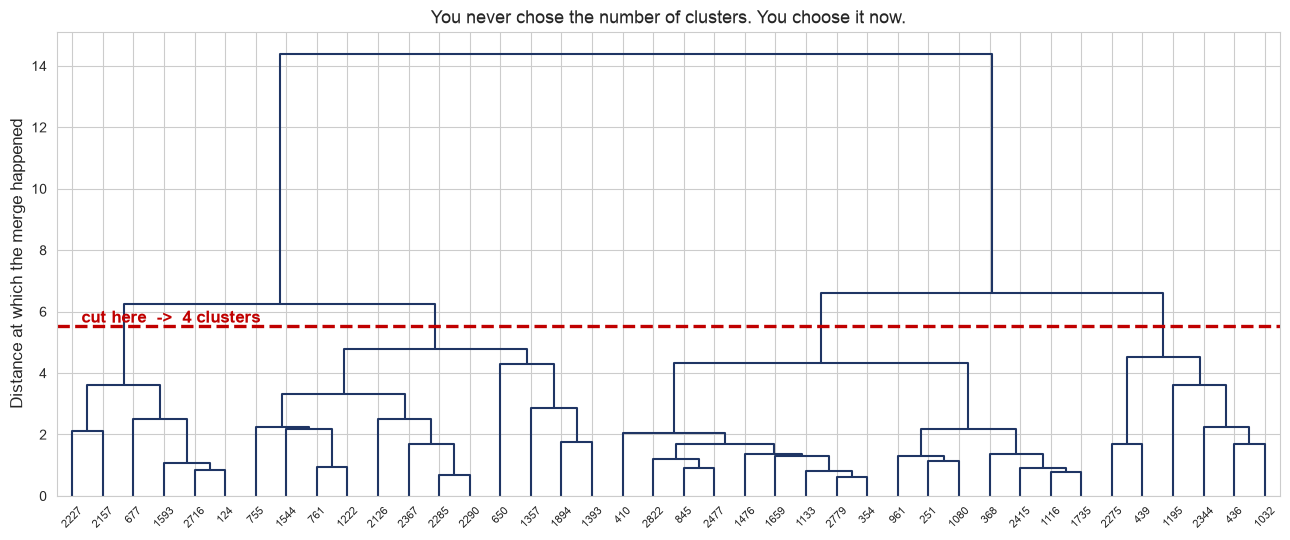

Cutting at 4 clusters gives sizes: [ 6 12 16  6]


In [15]:
# The same tree, with a cut line drawn on it
K_CUT = K

plt.figure(figsize=(13, 5.5))
dendrogram(Z, labels=samp.index.tolist(), leaf_font_size=8,
           color_threshold=0, above_threshold_color='#1F3564')

heights = np.sort(Z[:, 2])
cut = (heights[-K_CUT] + heights[-K_CUT + 1]) / 2 if K_CUT > 1 else heights[-1] * 1.1
plt.axhline(cut, color='#C00000', ls='--', lw=2.4)
plt.annotate(f'cut here  ->  {K_CUT} clusters', (0.02, cut),
             xycoords=('axes fraction', 'data'), va='bottom',
             fontsize=12, fontweight='bold', color='#C00000')
plt.ylabel('Distance at which the merge happened', fontsize=12)
plt.title('You never chose the number of clusters. You choose it now.', fontsize=13)
plt.tight_layout(); plt.show()

lab = fcluster(Z, K_CUT, criterion='maxclust')
print(f'Cutting at {K_CUT} clusters gives sizes: {np.bincount(lab)[1:]}')

---
# Section 5: Linkage Changes the Answer

Same houses. Same distances. Four rules for measuring the gap between two groups.

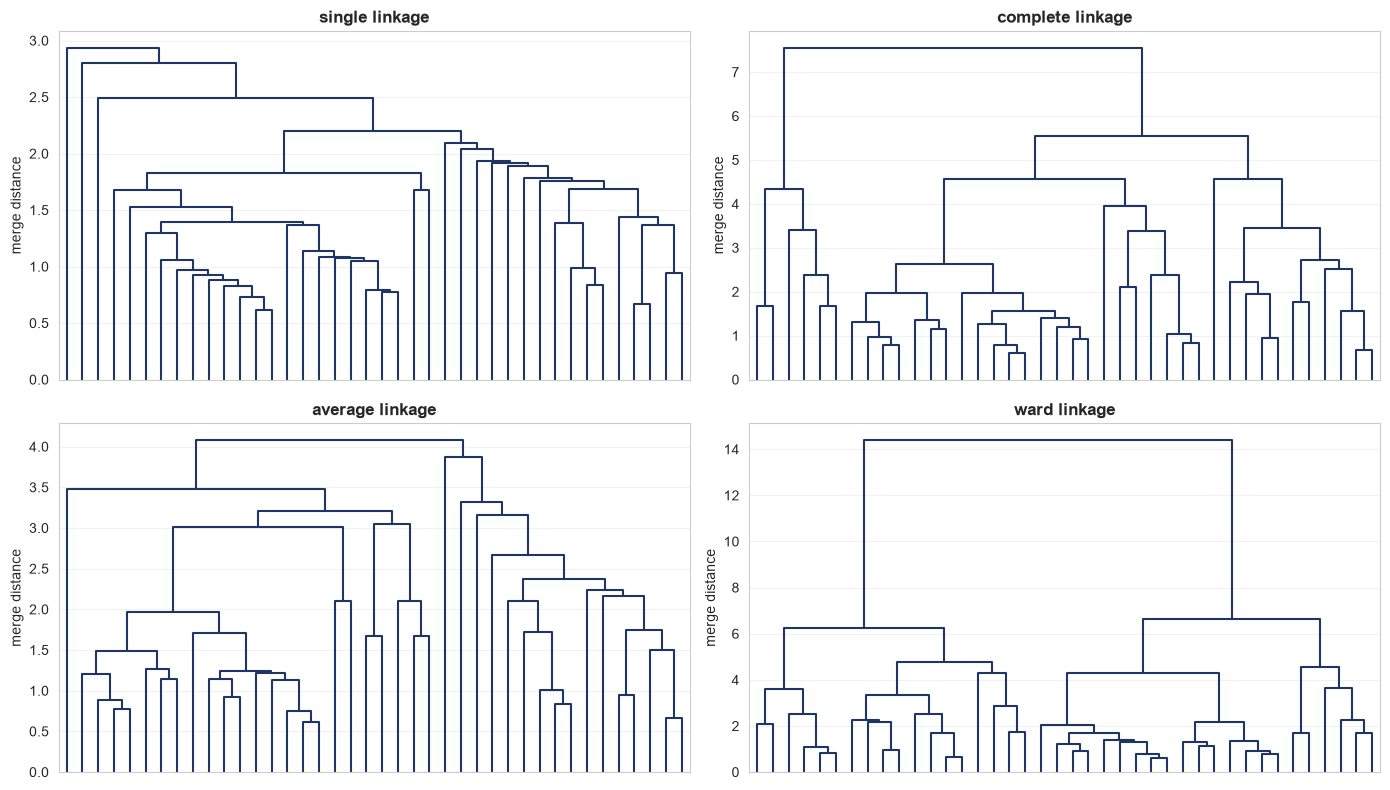

single   : distance between the CLOSEST members of two groups
complete : distance between the FURTHEST members
average  : the mean across every pair
ward     : the merge that increases total spread the least

Look at the single linkage tree. One long chain, everything joining one
at a time. That is the chaining effect, and it is why single linkage
is rarely used on data like this.


In [16]:
LINKAGES = ['single', 'complete', 'average', 'ward']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for a_, m in zip(axes.ravel(), LINKAGES):
    Zm = linkage(Xs_samp, method=m)
    dendrogram(Zm, ax=a_, no_labels=True, color_threshold=0,
               above_threshold_color='#1F3564')
    a_.set_title(f'{m} linkage', fontsize=12.5, fontweight='bold')
    a_.set_ylabel('merge distance')
    a_.grid(axis='y', alpha=.25)
plt.tight_layout(); plt.show()

print('single   : distance between the CLOSEST members of two groups')
print('complete : distance between the FURTHEST members')
print('average  : the mean across every pair')
print('ward     : the merge that increases total spread the least')
print()
print('Look at the single linkage tree. One long chain, everything joining one')
print('at a time. That is the chaining effect, and it is why single linkage')
print('is rarely used on data like this.')

In [17]:
# What does each linkage do at the same number of clusters?
print(f'CLUSTER SIZES AT k = {K}, BY LINKAGE')
print()
for m in LINKAGES:
    hc = AgglomerativeClustering(n_clusters=K, linkage=m).fit(Xs)
    sizes = np.bincount(hc.labels_)
    s = silhouette_score(Xs, hc.labels_)
    print(f'   {m:9} sizes {str(sizes):<28} silhouette {s:.4f}')
print()
print('Single linkage usually produces one huge cluster and a few singletons.')
print('That is the chaining effect again, on the full dataset.')

CLUSTER SIZES AT k = 4, BY LINKAGE

   single    sizes [2926    1    2    1]        silhouette 0.7416
   complete  sizes [   4  347    2 2577]        silhouette 0.2947
   average   sizes [2924    3    2    1]        silhouette 0.7694
   ward      sizes [1553  468  905    4]        silhouette 0.2251

Single linkage usually produces one huge cluster and a few singletons.
That is the chaining effect again, on the full dataset.


---
# Section 6: Do the Two Methods Agree?

In [18]:
hc = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(Xs)
work['hier'] = hc.labels_

ct = pd.crosstab(work['kmeans'], work['hier'])
print(f'k-means (rows) against hierarchical, ward (columns).  k = {K}')
print(ct.to_string())
print()
print('A clean diagonal would mean the two methods found the same groups.')
print('Cluster NUMBERS are arbitrary, so look for one large value per row,')
print('not for the numbers to match.')

k-means (rows) against hierarchical, ward (columns).  k = 4
hier       0    1    2  3
kmeans                   
0         93   76  750  0
1       1185    0   19  0
2          0  375   51  4
3        275   17   85  0

A clean diagonal would mean the two methods found the same groups.
Cluster NUMBERS are arbitrary, so look for one large value per row,
not for the numbers to match.


In [19]:
# How often do the two methods put a pair of houses together?
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(work['kmeans'], work['hier'])
nmi = normalized_mutual_info_score(work['kmeans'], work['hier'])

print(f'Adjusted Rand Index     : {ari:.4f}')
print(f'Normalized Mutual Info  : {nmi:.4f}')
print()
print('  1.0  identical groupings')
print('  0.0  no more agreement than random chance')
print()
print('These compare two clusterings against each other. Neither is a measure of')
print('correctness, because there is nothing to be correct about.')

Adjusted Rand Index     : 0.5822
Normalized Mutual Info  : 0.5508

  1.0  identical groupings
  0.0  no more agreement than random chance

These compare two clusterings against each other. Neither is a measure of
correctness, because there is nothing to be correct about.


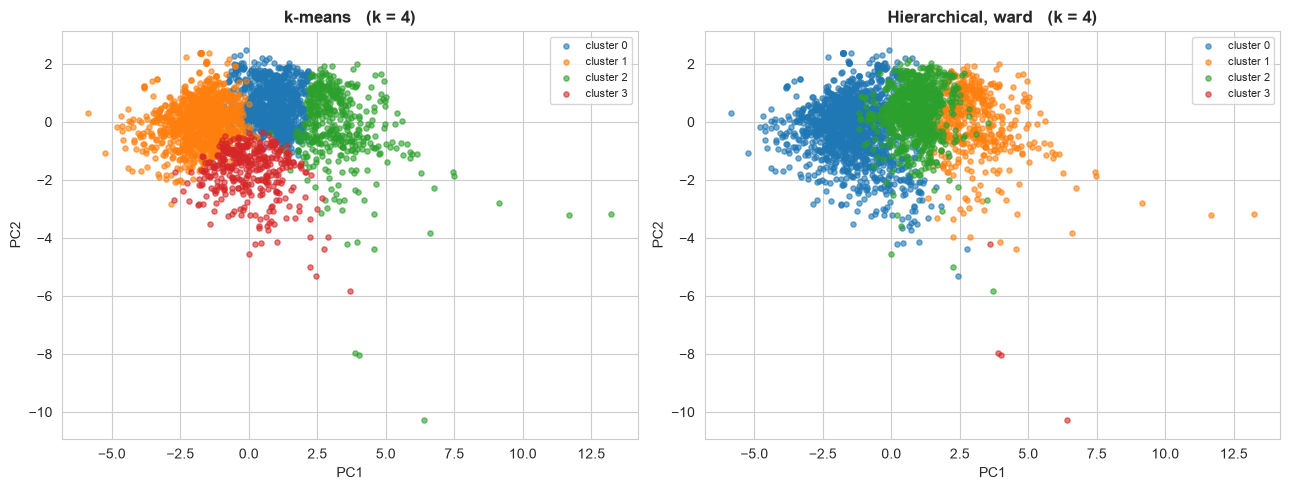

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a_, lab_, name in [(ax[0], work['kmeans'], 'k-means'),
                       (ax[1], work['hier'], 'Hierarchical, ward')]:
    for c in sorted(lab_.unique()):
        m = lab_ == c
        a_.scatter(Z2[m.values, 0], Z2[m.values, 1], s=14, alpha=.6, label=f'cluster {c}')
    a_.set_xlabel('PC1'); a_.set_ylabel('PC2')
    a_.set_title(f'{name}   (k = {K})', fontsize=12.5, fontweight='bold')
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

---
# Section 7: Are These Groups Real?

The uncomfortable section, and the one your project will be graded on.

## 7.1 Every algorithm returns clusters, including on noise

Generate pure random numbers, cluster them, and see what you get.

In [21]:
rng = np.random.default_rng(SEED)
noise = rng.normal(0, 1, size=Xs.shape)          # same shape, no structure at all

km_noise = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(noise)

print(f'Clustering {noise.shape[0]:,} rows of PURE RANDOM NUMBERS into {K} groups')
print(f'   cluster sizes : {np.bincount(km_noise.labels_)}')
print(f'   silhouette    : {silhouette_score(noise, km_noise.labels_):.4f}')
print()
print(f'Our real Ames data at k={K}: silhouette {silhouette_score(Xs, km.labels_):.4f}')
print()
print('The algorithm did not complain. It returned four tidy groups from noise.')
print('Compare the two silhouette scores. That difference is your evidence.')

Clustering 2,930 rows of PURE RANDOM NUMBERS into 4 groups
   cluster sizes : [752 749 672 757]
   silhouette    : 0.0808

Our real Ames data at k=4: silhouette 0.2642

The algorithm did not complain. It returned four tidy groups from noise.
Compare the two silhouette scores. That difference is your evidence.


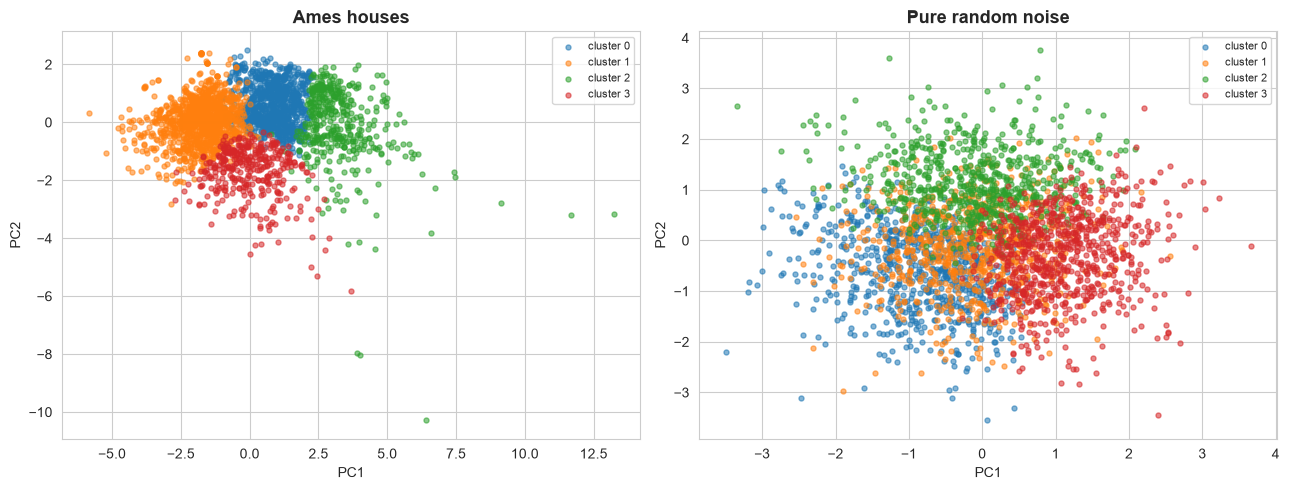

Both pictures look like clusters. Only one of them is.


In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pn = PCA(n_components=2).fit_transform(noise)
for a_, dat, lab_, name in [(ax[0], Z2, km.labels_, 'Ames houses'),
                            (ax[1], pn, km_noise.labels_, 'Pure random noise')]:
    for c in range(K):
        m = lab_ == c
        a_.scatter(dat[m, 0], dat[m, 1], s=13, alpha=.55, label=f'cluster {c}')
    a_.set_title(name, fontsize=13, fontweight='bold')
    a_.set_xlabel('PC1'); a_.set_ylabel('PC2'); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

print('Both pictures look like clusters. Only one of them is.')

## 7.2 Does the answer survive a change of seed?

k-means starts from random positions. If the groups are real, they should come
back the same way every time.

In [23]:
base = KMeans(n_clusters=K, n_init=20, random_state=0).fit(Xs).labels_
print('Agreement with the first run, across different seeds:')
for s in [1, 7, 42, 99, 123]:
    lab_ = KMeans(n_clusters=K, n_init=20, random_state=s).fit(Xs).labels_
    print(f'   seed {s:>3}:  ARI = {adjusted_rand_score(base, lab_):.4f}')
print()
print('Close to 1.0 means the structure is stable.')
print('Much lower means you are reading noise.')

Agreement with the first run, across different seeds:
   seed   1:  ARI = 0.9932
   seed   7:  ARI = 0.9992
   seed  42:  ARI = 0.7589
   seed  99:  ARI = 0.9968
   seed 123:  ARI = 0.9976

Close to 1.0 means the structure is stable.
Much lower means you are reading noise.


## 7.3 Does the answer survive a change of sample?

Cluster half the houses, then the other half. If the groups are real, the profiles
should look alike.

In [24]:
half = work.sample(frac=0.5, random_state=1).index
A = work.loc[half]
B = work.drop(half)

for name, sub in [('First half', A), ('Second half', B)]:
    Xh = scaler.transform(sub[FEATURES])
    kmh = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Xh)
    prof = sub.assign(c=kmh.labels_).groupby('c')['SalePrice'].agg(['size', 'mean'])
    prof = prof.sort_values('mean')
    print(f'{name}: average price per cluster, smallest first')
    print('   ' + '   '.join(f'${m:,.0f} (n={int(n)})' for n, m in prof.values))
print()
print('Similar price ladders in both halves is reassuring.')
print('Wildly different ladders means the groups depend on which houses you looked at.')

First half: average price per cluster, smallest first
   $126,779 (n=620)   $157,368 (n=205)   $197,563 (n=429)   $321,034 (n=211)
Second half: average price per cluster, smallest first
   $127,768 (n=646)   $191,626 (n=578)   $303,046 (n=238)   $318,000 (n=3)

Similar price ladders in both halves is reassuring.
Wildly different ladders means the groups depend on which houses you looked at.


## 7.4 The three questions to answer before you believe any clustering

1. **Is the silhouette clearly better than on random data of the same shape?**
2. **Does the same structure come back under a different seed and a different sample?**
3. **Can you name the clusters in words somebody in the domain would use?**

If you cannot answer yes to all three, say so in your report. Reporting
"we found four groups but they were not stable" is a real finding and earns marks.